# Animal Classification Using ResNet50 Transfer Learning



Objective

To develop an image classification system capable of classifying animals into four categories: Buffalo, Elephant, Rhino, and Zebra using transfer learning with a pretrained ResNet50 convolutional neural network.

Total Images: 4000

Buffalo    → 1000
Elephant   → 1000
Rhino      → 1000
Zebra      → 1000

Pretrained Model: ResNet50
Pretrained Weights: ImageNet
Input Size: 224 × 224 × 3
Output Classes: 4

STAGE 1
ResNet50 frozen
       ↓
Feature Extraction
       ↓
Train Classification Head


STAGE 2
Last ResNet50 layers unfrozen
       ↓
Fine-Tuning
       ↓
Improve Animal Classification

import libaries

In [1]:
import os
import zipfile
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

# Find Your Uploaded ZIP File

In [2]:
import os

for file in os.listdir("/content"):
    print(file)

.config
archive.zip
sample_data


In [3]:
ZIP_PATH = "/content/archive.zip"

In [4]:
ZIP_PATH = "/content/archive.zip"

print("ZIP exists:", os.path.exists(ZIP_PATH))
print("ZIP path:", ZIP_PATH)

ZIP exists: True
ZIP path: /content/archive.zip


In [5]:
import zipfile

print("Is valid ZIP:", zipfile.is_zipfile(ZIP_PATH))

Is valid ZIP: True


see whats inside the zip

In [6]:
with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    files = zip_ref.namelist()

print("Total files inside ZIP:", len(files))

for file in files[:30]:
    print(file)

Total files inside ZIP: 4000
Data/Buffalo/Buffalo_1.jpg
Data/Buffalo/Buffalo_10.jpg
Data/Buffalo/Buffalo_100.jpg
Data/Buffalo/Buffalo_1000.jpg
Data/Buffalo/Buffalo_101.jpg
Data/Buffalo/Buffalo_102.jpg
Data/Buffalo/Buffalo_103.jpg
Data/Buffalo/Buffalo_104.jpg
Data/Buffalo/Buffalo_105.jpg
Data/Buffalo/Buffalo_106.jpg
Data/Buffalo/Buffalo_107.jpg
Data/Buffalo/Buffalo_108.jpg
Data/Buffalo/Buffalo_109.jpg
Data/Buffalo/Buffalo_11.jpg
Data/Buffalo/Buffalo_110.jpg
Data/Buffalo/Buffalo_111.jpg
Data/Buffalo/Buffalo_112.jpg
Data/Buffalo/Buffalo_113.jpg
Data/Buffalo/Buffalo_114.jpg
Data/Buffalo/Buffalo_115.jpg
Data/Buffalo/Buffalo_116.jpg
Data/Buffalo/Buffalo_117.jpg
Data/Buffalo/Buffalo_118.jpg
Data/Buffalo/Buffalo_119.jpg
Data/Buffalo/Buffalo_12.jpg
Data/Buffalo/Buffalo_120.jpg
Data/Buffalo/Buffalo_121.jpg
Data/Buffalo/Buffalo_122.jpg
Data/Buffalo/Buffalo_123.jpg
Data/Buffalo/Buffalo_124.jpg


# extract the dataset

In [7]:
EXTRACT_PATH = "/content/animal_dataset"

os.makedirs(EXTRACT_PATH, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_PATH)

print("Dataset extracted successfully!")

Dataset extracted successfully!


checking

In [8]:
for root, dirs, files in os.walk(EXTRACT_PATH):
    level = root.replace(EXTRACT_PATH, "").count(os.sep)

    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")

animal_dataset/
  Data/
    Zebra/
    Buffalo/
    Rhino/
    Elephant/


Automatically Find Animal Folder

In [9]:
animal_classes = ["Buffalo", "Elephant", "Rhino", "Zebra"]

class_paths = {}

for root, dirs, files in os.walk(EXTRACT_PATH):
    for animal in animal_classes:
        if animal in dirs:
            class_paths[animal] = os.path.join(root, animal)

print("Found folders:")

for animal, path in class_paths.items():
    print(animal, "->", path)

Found folders:
Buffalo -> /content/animal_dataset/Data/Buffalo
Elephant -> /content/animal_dataset/Data/Elephant
Rhino -> /content/animal_dataset/Data/Rhino
Zebra -> /content/animal_dataset/Data/Zebra


checking number of images

In [10]:
for animal, path in class_paths.items():

    image_files = [
        f for f in os.listdir(path)
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp", ".webp")
        )
    ]

    print(f"{animal}: {len(image_files)} images")

Buffalo: 1000 images
Elephant: 1000 images
Rhino: 1000 images
Zebra: 1000 images


Set Dataset Directory

In [11]:
DATASET_DIR = "/content/animal_dataset_clean"

os.makedirs(DATASET_DIR, exist_ok=True)

In [12]:
print(class_paths)

{'Buffalo': '/content/animal_dataset/Data/Buffalo', 'Elephant': '/content/animal_dataset/Data/Elephant', 'Rhino': '/content/animal_dataset/Data/Rhino', 'Zebra': '/content/animal_dataset/Data/Zebra'}


get dataset directory

In [13]:
DATASET_DIR = "/content/animal_dataset/Data"

print("Dataset directory:", DATASET_DIR)
print("Exists:", os.path.exists(DATASET_DIR))

Dataset directory: /content/animal_dataset/Data
Exists: True


checking animal classes

In [14]:
animal_classes = sorted(os.listdir(DATASET_DIR))

print("Classes:")
for animal in animal_classes:
    print(animal)

Classes:
Buffalo
Elephant
Rhino
Zebra


# Set Image Parameters
ResNet50 expects images of size 224 × 224 × 3.


In [15]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42
NUM_CLASSES = 4

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Number of classes:", NUM_CLASSES)

Image size: (224, 224)
Batch size: 32
Number of classes: 4


# Loading training dataset

In [16]:
train_dataset = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical"
)

Found 4000 files belonging to 4 classes.
Using 3200 files for training.


# Load validation dataset

In [17]:
validation_dataset = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical"
)

Found 4000 files belonging to 4 classes.
Using 800 files for validation.


get class names

In [18]:
class_names = train_dataset.class_names

print("Class names:")
print(class_names)

Class names:
['Buffalo', 'Elephant', 'Rhino', 'Zebra']


# display sample images

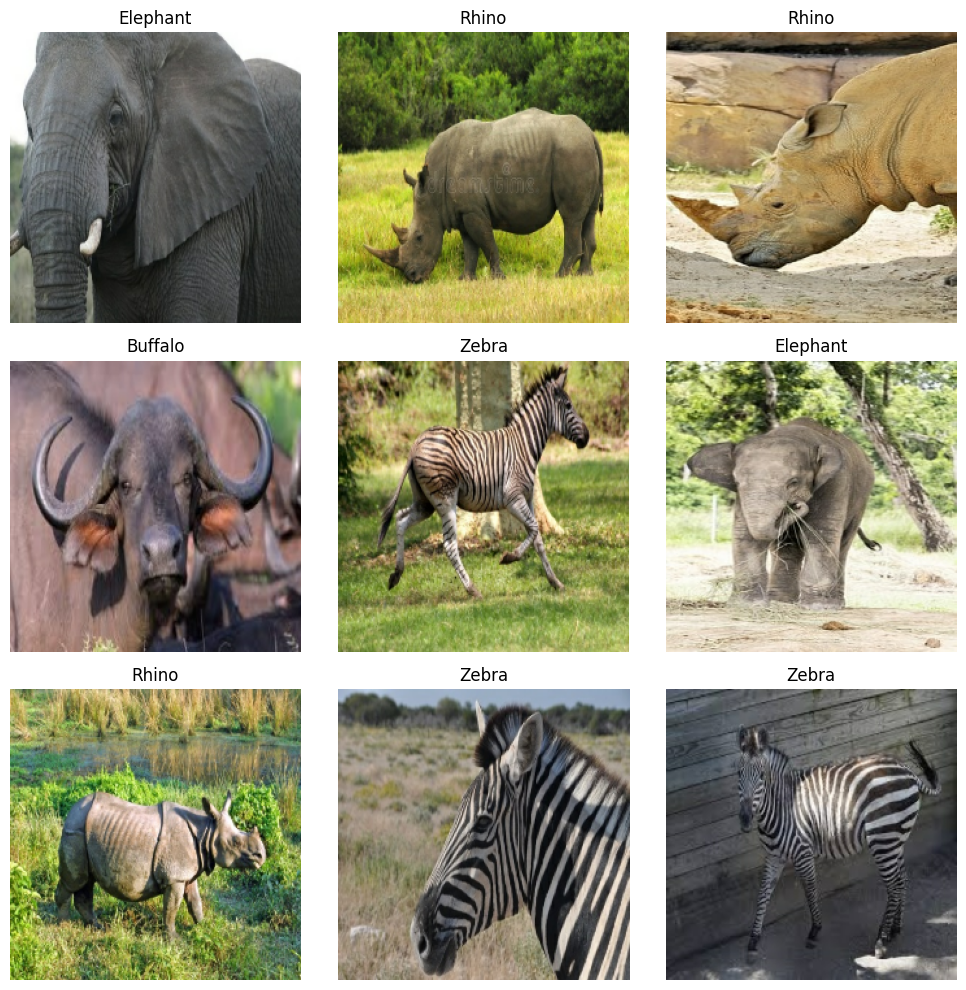

In [19]:
plt.figure(figsize=(10, 10))

for images, labels in train_dataset.take(1):

    for i in range(9):

        plt.subplot(3, 3, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))

        label_index = np.argmax(labels[i].numpy())

        plt.title(class_names[label_index])

        plt.axis("off")

plt.tight_layout()
plt.show()

# Data Augmentation

In [20]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1)
])

# using ResNet 50

In [21]:
base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [22]:
base_model.summary()

Model: "resnet50"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 23,587,712 (89.98 MB)

 Trainable params: 23,534,592 (89.78 MB)

 Non-trainable params: 53,120 (207.50 KB)

In [23]:
base_model.trainable = False

# bulid a animal lassificatiion model

In [24]:
inputs = layers.Input(
    shape=(224, 224, 3)
)

x = data_augmentation(inputs)

x = preprocess_input(x)

x = base_model(
    x,
    training=False
)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dense(
    256,
    activation="relu"
)(x)

x = layers.Dropout(0.5)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

model = models.Model(
    inputs,
    outputs
)

model summary

In [25]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential          │ (None, 224, 224,  │          0 │ input_layer_1[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ sequential[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ sequential[0][0]  │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ sequential[0][0]  │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 7, 7,      │ 23,587,712 │ add[0][0]         │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ resnet50[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │    524,544 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 4)         │      1,028 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 24,113,284 (91.98 MB)

 Trainable params: 525,572 (2.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

compile model

In [26]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

create a model check point

In [27]:
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "/content/best_resnet50_animal.keras",
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

early stoping

In [28]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce learining rate

In [29]:
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

resnet feature extracter

In [30]:
history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=10,
    callbacks=[
        checkpoint,
        early_stopping,
        reduce_lr
    ]
)

Epoch 1/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step - accuracy: 0.6723 - loss: 0.8504
Epoch 1: val_accuracy improved from None to 0.97625, saving model to /content/best_resnet50_animal.keras

Epoch 1: finished saving model to /content/best_resnet50_animal.keras
100/100 ━━━━━━━━━━━━━━━━━━━━ 32s 199ms/step - accuracy: 0.8072 - loss: 0.5290 - val_accuracy: 0.9762 - val_loss: 0.1032 - learning_rate: 1.0000e-04
Epoch 2/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step - accuracy: 0.9360 - loss: 0.1929
Epoch 2: val_accuracy did not improve from 0.97625
100/100 ━━━━━━━━━━━━━━━━━━━━ 19s 187ms/step - accuracy: 0.9375 - loss: 0.1887 - val_accuracy: 0.9700 - val_loss: 0.0712 - learning_rate: 1.0000e-04
Epoch 3/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step - accuracy: 0.9487 - loss: 0.1505
Epoch 3: val_accuracy improved from 0.97625 to 0.98250, saving model to /content/best_resnet50_animal.keras

Epoch 3: finished saving model to /content/best_resnet50_animal.keras
100/100 ━━━━━━━━━━━━━━━━━━━━ 18s 1

plot accuarcy

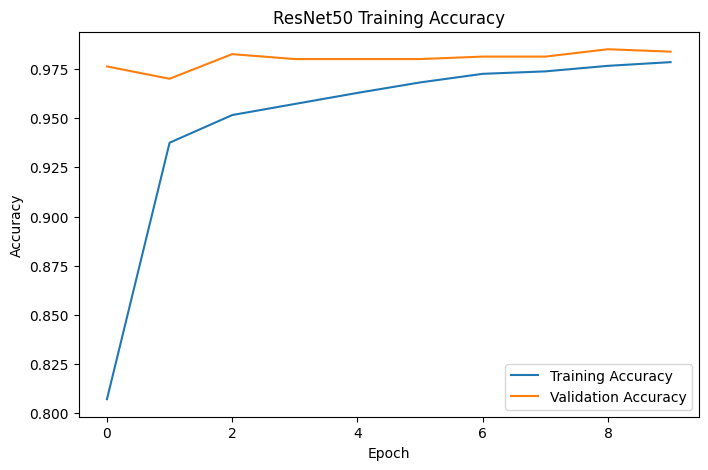

In [31]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ResNet50 Training Accuracy")

plt.legend()
plt.show()

plot loss

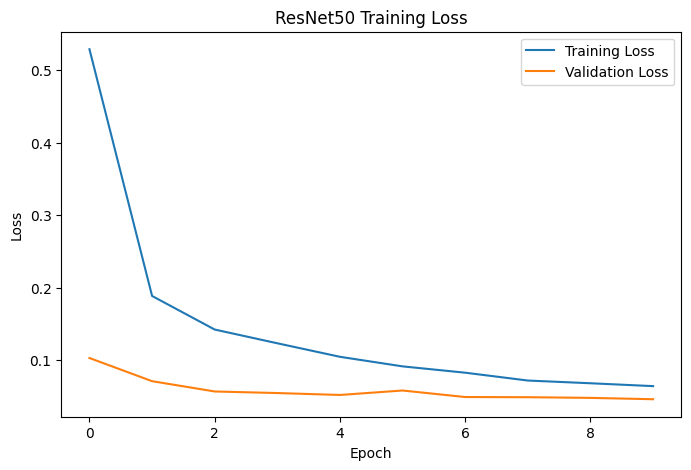

In [32]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ResNet50 Training Loss")

plt.legend()
plt.show()

# fine tuning

Fine-tuning means taking a pre-trained model and training some of its layers a little more on your own dataset.

For example, ResNet50 has already learned general image features such as:

edges
colors
shapes
textures
patterns

Instead of training ResNet50 from the beginning, we reuse what it already learned and slightly adjust it for our specific task.

In [33]:
base_model.trainable = True

Then freeze most of the earlier layers:


In [34]:
for layer in base_model.layers[:-20]:
    layer.trainable = False

Check Trainable Layers

In [35]:
for layer in base_model.layers:
    if layer.trainable:
        print(layer.name)

conv5_block2_1_conv
conv5_block2_1_bn
conv5_block2_1_relu
conv5_block2_2_conv
conv5_block2_2_bn
conv5_block2_2_relu
conv5_block2_3_conv
conv5_block2_3_bn
conv5_block2_add
conv5_block2_out
conv5_block3_1_conv
conv5_block3_1_bn
conv5_block3_1_relu
conv5_block3_2_conv
conv5_block3_2_bn
conv5_block3_2_relu
conv5_block3_3_conv
conv5_block3_3_bn
conv5_block3_add
conv5_block3_out


recompile with small learning rate

In [36]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

fine tune with ResNet50

In [37]:
fine_tune_history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=10,
    callbacks=[
        checkpoint,
        early_stopping,
        reduce_lr
    ]
)

Epoch 1/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step - accuracy: 0.9747 - loss: 0.0834
Epoch 1: val_accuracy did not improve from 0.98500
100/100 ━━━━━━━━━━━━━━━━━━━━ 33s 232ms/step - accuracy: 0.9731 - loss: 0.0803 - val_accuracy: 0.9812 - val_loss: 0.0502 - learning_rate: 1.0000e-05
Epoch 2/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 180ms/step - accuracy: 0.9823 - loss: 0.0571
Epoch 2: val_accuracy did not improve from 0.98500

Epoch 2: ReduceLROnPlateau reducing learning rate to 1.9999999494757505e-06.
100/100 ━━━━━━━━━━━━━━━━━━━━ 22s 216ms/step - accuracy: 0.9825 - loss: 0.0547 - val_accuracy: 0.9837 - val_loss: 0.0486 - learning_rate: 1.0000e-05
Epoch 3/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step - accuracy: 0.9847 - loss: 0.0533
Epoch 3: val_accuracy improved from 0.98500 to 0.98875, saving model to /content/best_resnet50_animal.keras

Epoch 3: finished saving model to /content/best_resnet50_animal.keras
100/100 ━━━━━━━━━━━━━━━━━━━━ 42s 222ms/step - accuracy: 0.9844 - loss: 0.0508 - v

load the best ResNEt50 model

In [38]:
best_model = tf.keras.models.load_model(
    "/content/best_resnet50_animal.keras"
)

print("Best ResNet50 model loaded successfully!")

Best ResNet50 model loaded successfully!


evalute model

In [39]:
loss, accuracy = best_model.evaluate(
    validation_dataset
)

print("Validation Loss:", loss)
print("Validation Accuracy:", accuracy)

25/25 ━━━━━━━━━━━━━━━━━━━━ 7s 133ms/step - accuracy: 0.9900 - loss: 0.0431
Validation Loss: 0.04314878582954407
Validation Accuracy: 0.9900000095367432


generate prediction

In [40]:
y_true = []
y_pred = []

for images, labels in validation_dataset:

    predictions = best_model.predict(
        images,
        verbose=0
    )

    predicted_classes = np.argmax(
        predictions,
        axis=1
    )

    true_classes = np.argmax(
        labels.numpy(),
        axis=1
    )

    y_pred.extend(predicted_classes)
    y_true.extend(true_classes)

# classification report

In [42]:
print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)

              precision    recall  f1-score   support

     Buffalo       0.99      0.99      0.99       185
    Elephant       0.99      0.98      0.98       201
       Rhino       0.97      0.99      0.98       191
       Zebra       1.00      1.00      1.00       223

    accuracy                           0.99       800
   macro avg       0.99      0.99      0.99       800
weighted avg       0.99      0.99      0.99       800



confusion matrix

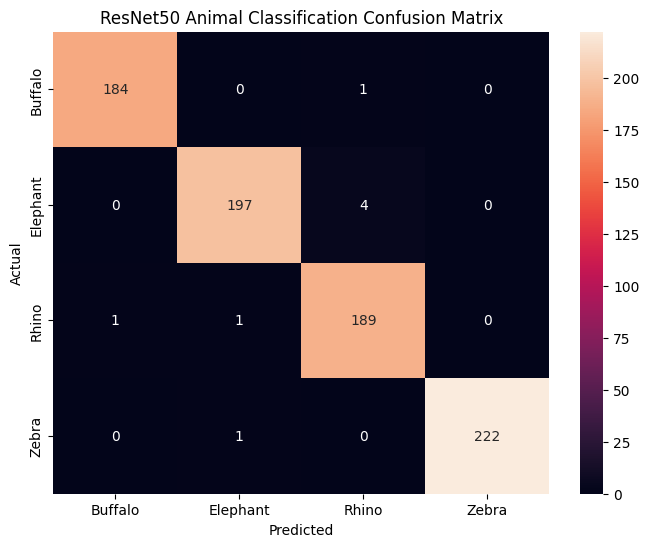

In [43]:
cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title(
    "ResNet50 Animal Classification Confusion Matrix"
)

plt.show()

upload a new image

In [44]:
from google.colab import files

uploaded = files.upload()

Saving 22222.jpg to 22222.jpg


process new image


In [45]:
from tensorflow.keras.utils import load_img
from tensorflow.keras.utils import img_to_array

image_path = list(uploaded.keys())[0]

img = load_img(
    image_path,
    target_size=(224, 224)
)

img_array = img_to_array(img)

img_array = np.expand_dims(
    img_array,
    axis=0
)

img_array = preprocess_input(
    img_array
)

predict the animal

In [46]:
prediction = best_model.predict(
    img_array
)

predicted_index = np.argmax(
    prediction[0]
)

predicted_class = class_names[
    predicted_index
]

confidence = (
    prediction[0][predicted_index] * 100
)

print("Predicted Animal:", predicted_class)
print(
    "Confidence:",
    f"{confidence:.2f}%"
)

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
Predicted Animal: Elephant
Confidence: 100.00%


display prediction

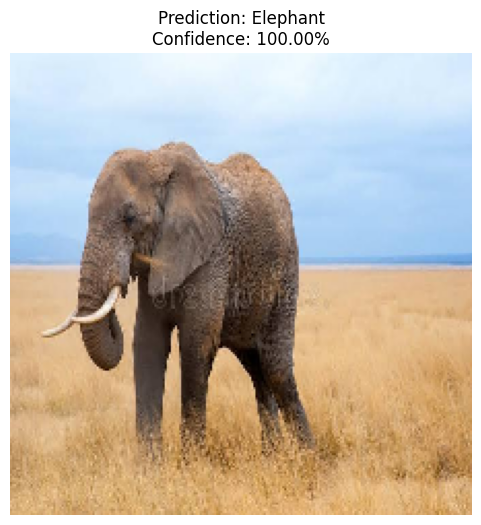

In [47]:
plt.figure(figsize=(6, 6))

plt.imshow(img)

plt.title(
    f"Prediction: {predicted_class}\n"
    f"Confidence: {confidence:.2f}%"
)

plt.axis("off")

plt.show()

one more checking


In [48]:
from google.colab import files

uploaded = files.upload()

Saving ele.jpg to ele.jpg


In [49]:
from tensorflow.keras.utils import load_img
from tensorflow.keras.utils import img_to_array

image_path = list(uploaded.keys())[0]

img = load_img(
    image_path,
    target_size=(224, 224)
)

img_array = img_to_array(img)

img_array = np.expand_dims(
    img_array,
    axis=0
)

img_array = preprocess_input(
    img_array
)

In [50]:
prediction = best_model.predict(
    img_array
)

predicted_index = np.argmax(
    prediction[0]
)

predicted_class = class_names[
    predicted_index
]

confidence = (
    prediction[0][predicted_index] * 100
)

print("Predicted Animal:", predicted_class)
print(
    "Confidence:",
    f"{confidence:.2f}%"
)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
Predicted Animal: Elephant
Confidence: 99.94%


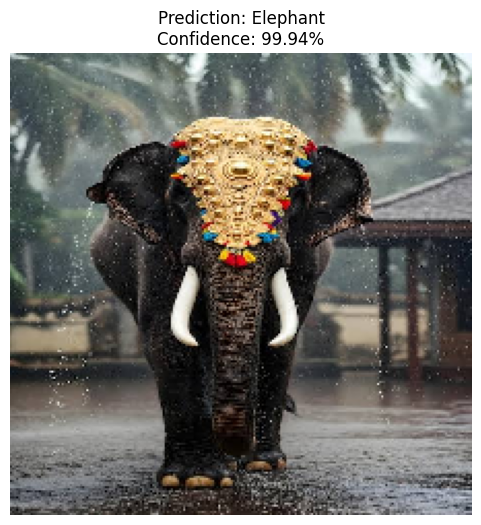

In [51]:
plt.figure(figsize=(6, 6))

plt.imshow(img)

plt.title(
    f"Prediction: {predicted_class}\n"
    f"Confidence: {confidence:.2f}%"
)

plt.axis("off")

plt.show()

python conversion to yolo

In [52]:

!pip install -q ultralytics


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 38.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 10.2 MB/s eta 0:00:00


In [53]:

import os

DATASET_DIR = "/content/animal_dataset/Data"

for animal in ["Buffalo", "Elephant", "Rhino", "Zebra"]:
    folder = os.path.join(DATASET_DIR, animal)
    print(animal, ":", len(os.listdir(folder)), "files")


Buffalo : 1000 files
Elephant : 1000 files
Rhino : 1000 files
Zebra : 1000 files


# prepare yolo classfication folders

In [54]:

import random
import shutil
from pathlib import Path

random.seed(42)

SOURCE = Path(DATASET_DIR)
DEST = Path("/content/yolo_animal_dataset")

classes = ["Buffalo", "Elephant", "Rhino", "Zebra"]
extensions = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

for animal in classes:
    files = [
        p for p in (SOURCE / animal).rglob("*")
        if p.is_file() and p.suffix.lower() in extensions
    ]

    random.shuffle(files)
    split = int(0.8 * len(files))

    for split_name, selected in [
        ("train", files[:split]),
        ("val", files[split:])
    ]:
        target = DEST / split_name / animal
        target.mkdir(parents=True, exist_ok=True)

        for i, src in enumerate(selected):
            shutil.copy2(src, target / f"{i}_{src.name}")

print("YOLO classification dataset prepared!")


YOLO classification dataset prepared!


# load a pretrained yolo classfication model


using yolov8n

In [55]:

from ultralytics import YOLO

model = YOLO("yolov8n-cls.pt")

print("YOLO classification model loaded!")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
YOLO classification model loaded!


# train the model

In [ ]:

results = model.train(
    data="/content/yolo_animal_dataset",
    epochs=20,
    imgsz=224,
    batch=16,
    patience=5,
    project="/content/runs",
    name="animal_yolo"
)


Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_animal_dataset, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=animal_yolo, nbs=64, nms=None, opset=None, optimize=False

# Evaluate the trained YOLO model

In [2]:
from ultralytics import YOLO
import os

# Load the trained model weights
model_path = "/content/runs/animal_yolo/weights/best.pt"
if os.path.exists(model_path):
    model = YOLO(model_path)
else:
    # Fallback to the base model if training weights aren't found
    model = YOLO("yolov8n-cls.pt")

metrics = model.val(
    data="/content/yolo_animal_dataset",
    split="val",
    imgsz=224
)

print("Validation results:")
print(metrics)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n-cls summary (fused): 30 layers, 2,715,880 parameters, 0 gradients, 3.3 GFLOPs
train: /content/yolo_animal_dataset/train... found 3200 images in 4 classes ✅ 
val: /content/yolo_animal_dataset/val... found 800 images in 4 classes ✅ 
test: None...
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1826.7±556.7 MB/s, size: 48.8 KB)
val: Scanning /content/yolo_animal_dataset/val... 800 images, 0 corrupt: 100% ━━━━━━━━━━━━ 800/800 5.0Kit/s 0.2s
val: New cache created: /content/yolo_animal_dataset/val.cache
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 50/50 11.8it/s 4.3s
                   all          0          0
Speed: 0.3ms preprocess, 1.4ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to /content/runs/classify/val
Validation results:
ultralytics.utils.metrics.ClassifyMetrics object with attributes:

confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix 

# display training result

In [5]:

from IPython.display import display, Image
from pathlib import Path

results_dir = Path("/content/runs/animal_yolo")

results_image = results_dir / "results.png"

if results_image.exists():
    display(Image(filename=str(results_image)))
else:
    print("Training results image not found.")
    print("Check:", results_dir)


Training results image not found.
Check: /content/runs/animal_yolo


In [4]:

import os
from IPython.display import display, Image

for root, dirs, files in os.walk("/content/runs"):
    if "results.png" in files:
        path = os.path.join(root, "results.png")
        print("Results found:", path)
        display(Image(filename=path))


In [6]:

import os

print("Current directory:", os.getcwd())
print("YOLO runs folder exists:", os.path.exists("/content/runs"))

for root, dirs, files in os.walk("/content/runs"):
    print("\nFolder:", root)
    print("Files:", files[:15])


Current directory: /content
YOLO runs folder exists: True

Folder: /content/runs
Files: []

Folder: /content/runs/animal_yolo
Files: ['args.yaml']

Folder: /content/runs/animal_yolo/weights
Files: []

Folder: /content/runs/classify
Files: []

Folder: /content/runs/classify/val
Files: ['val_batch0_pred.jpg', 'val_batch2_pred.jpg', 'val_batch1_labels.jpg', 'val_batch1_pred.jpg', 'confusion_matrix.png', 'val_batch2_labels.jpg', 'val_batch0_labels.jpg', 'confusion_matrix_normalized.png']


confusion_matrix.png


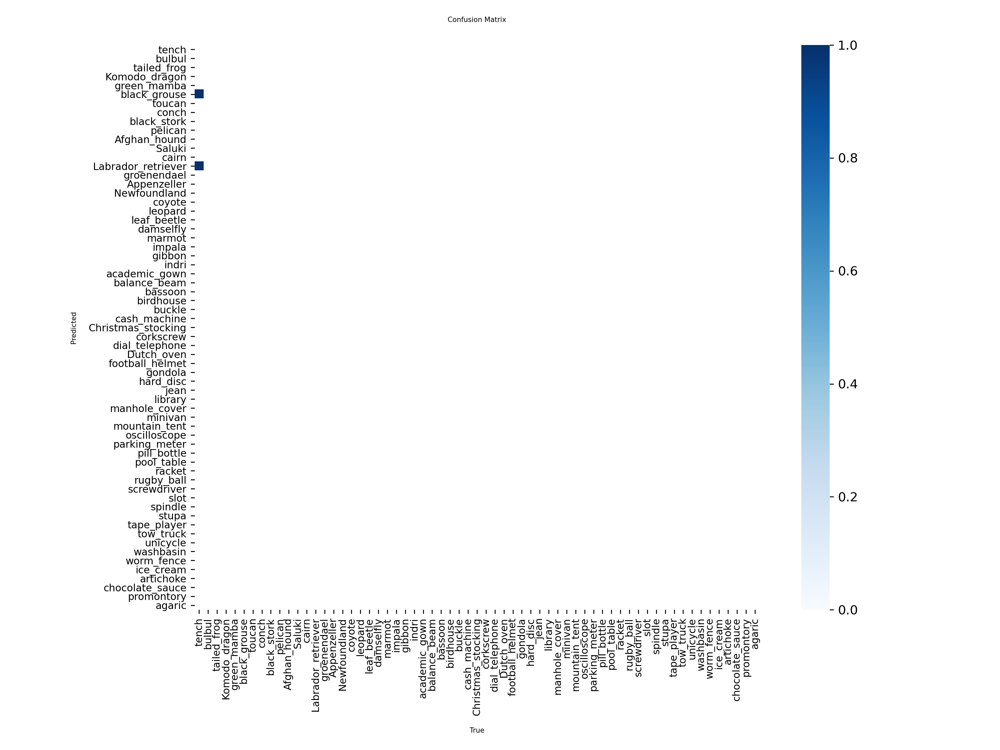

confusion_matrix_normalized.png


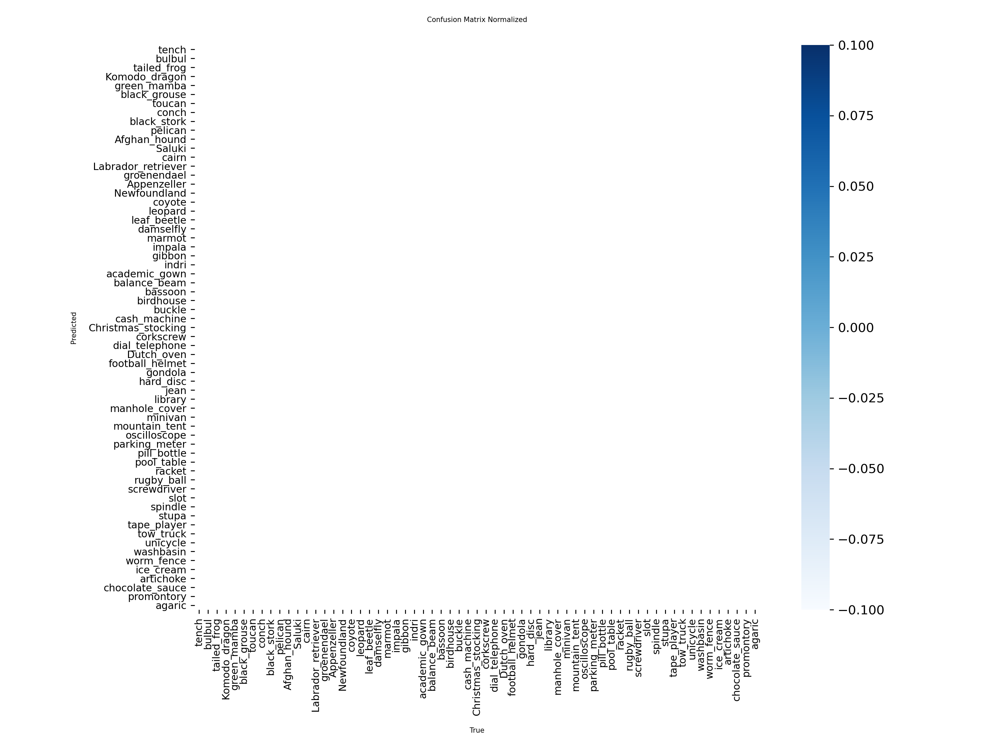

val_batch0_pred.jpg


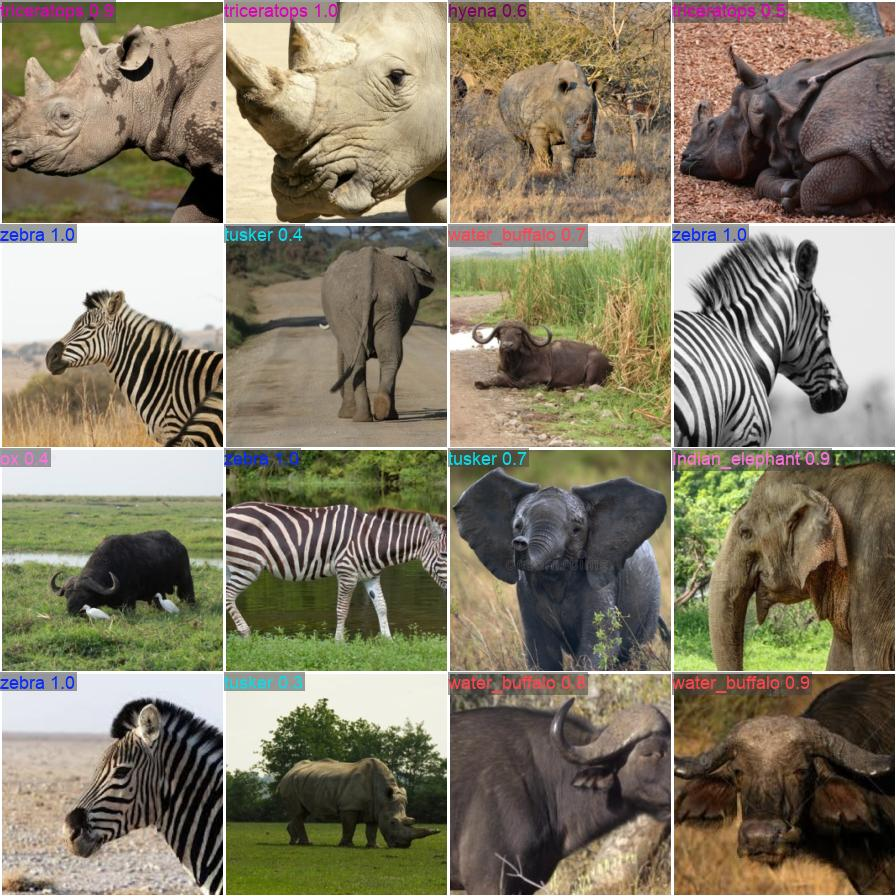

In [7]:

from IPython.display import display, Image
from pathlib import Path

val_dir = Path("/content/runs/classify/val")

for name in [
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "val_batch0_pred.jpg"
]:
    path = val_dir / name
    if path.exists():
        print(name)
        display(Image(filename=str(path)))


Displaying: confusion_matrix.png


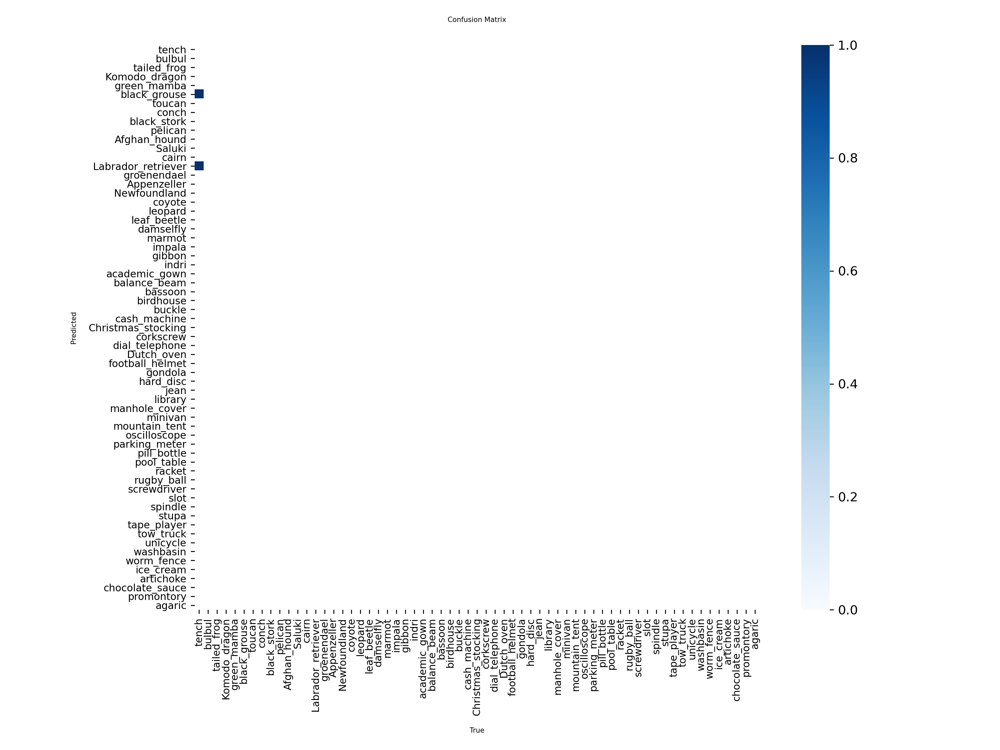

Displaying: confusion_matrix_normalized.png


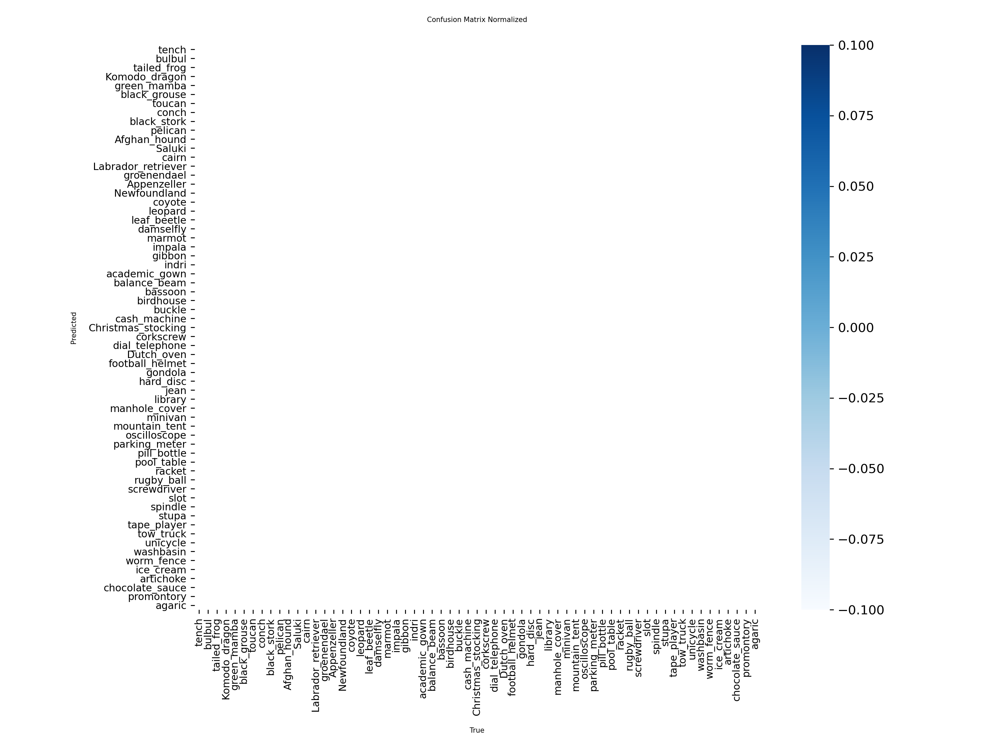

Displaying: val_batch0_pred.jpg


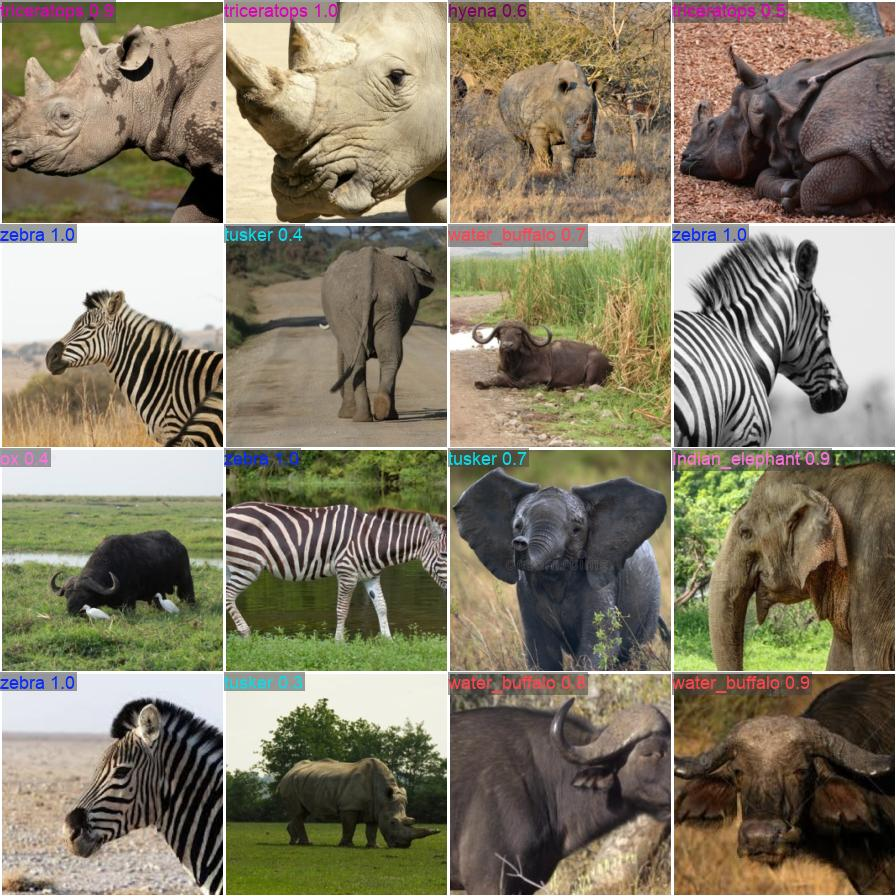

In [9]:
from IPython.display import display, Image
from pathlib import Path

val_dir = Path("/content/runs/classify/val")

# List of evaluation files to display
image_files = [
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "val_batch0_pred.jpg"
]

for name in image_files:
    path = val_dir / name
    if path.exists():
        print(f"Displaying: {name}")
        display(Image(filename=str(path)))
    else:
        print(f"Could not find: {name}")

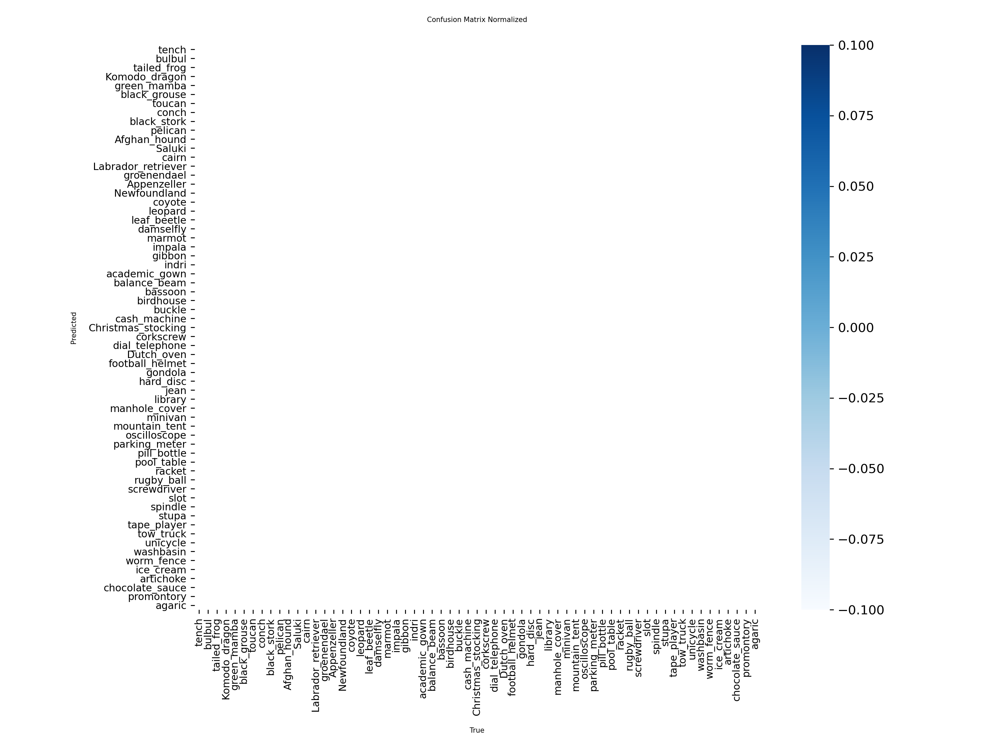

In [10]:

display(Image(filename="/content/runs/classify/val/confusion_matrix_normalized.png"))


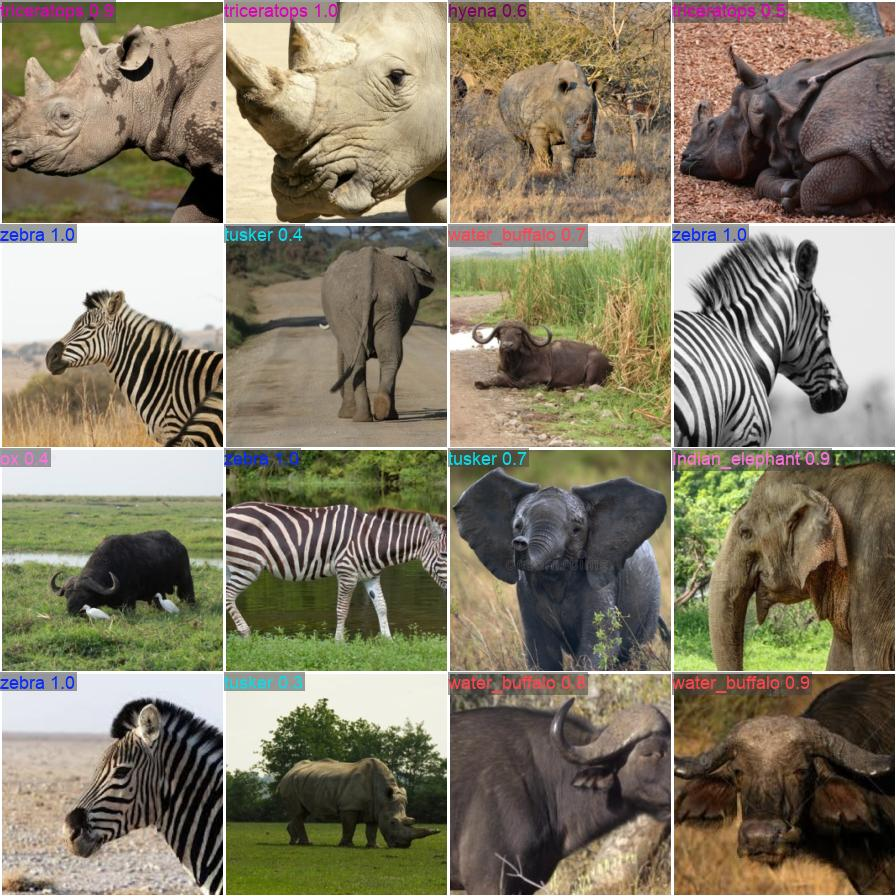

In [11]:

display(Image(filename="/content/runs/classify/val/val_batch0_pred.jpg"))


In [12]:

from pathlib import Path

for path in Path("/content/runs").rglob("*.pt"):
    print("Found model:", path)

print("Current model variable:", type(model).__name__)


Current model variable: YOLO


In [13]:
print("Model type:", type(model).__name__)
print("Model checkpoint:", model.ckpt_path)
print("Model names:", model.names)

Model type: YOLO
Model checkpoint: yolov8n-cls.pt
Model names: {0: 'tench', 1: 'goldfish', 2: 'great_white_shark', 3: 'tiger_shark', 4: 'hammerhead', 5: 'electric_ray', 6: 'stingray', 7: 'cock', 8: 'hen', 9: 'ostrich', 10: 'brambling', 11: 'goldfinch', 12: 'house_finch', 13: 'junco', 14: 'indigo_bunting', 15: 'robin', 16: 'bulbul', 17: 'jay', 18: 'magpie', 19: 'chickadee', 20: 'water_ouzel', 21: 'kite', 22: 'bald_eagle', 23: 'vulture', 24: 'great_grey_owl', 25: 'European_fire_salamander', 26: 'common_newt', 27: 'eft', 28: 'spotted_salamander', 29: 'axolotl', 30: 'bullfrog', 31: 'tree_frog', 32: 'tailed_frog', 33: 'loggerhead', 34: 'leatherback_turtle', 35: 'mud_turtle', 36: 'terrapin', 37: 'box_turtle', 38: 'banded_gecko', 39: 'common_iguana', 40: 'American_chameleon', 41: 'whiptail', 42: 'agama', 43: 'frilled_lizard', 44: 'alligator_lizard', 45: 'Gila_monster', 46: 'green_lizard', 47: 'African_chameleon', 48: 'Komodo_dragon', 49: 'African_crocodile', 50: 'American_alligator', 51: 'tri

In [14]:
from ultralytics import YOLO
from pathlib import Path

model = YOLO("yolov8n-cls.pt")

results = model.train(
    data="/content/yolo_animal_dataset",
    epochs=20,
    imgsz=224,
    batch=16,
    patience=5,
    project="/content/runs",
    name="animal_yolo",
    exist_ok=True,
    plots=True,
    save=True
)

best_path = Path("/content/runs/animal_yolo/weights/best.pt")

if best_path.exists():
    print("Training completed!")
    print("Best model:", best_path)
else:
    print("Best model file not found. Check the training output.")

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_animal_dataset, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=animal_yolo, nbs=64, nms=None, opset=None, optimize=False,

results.png


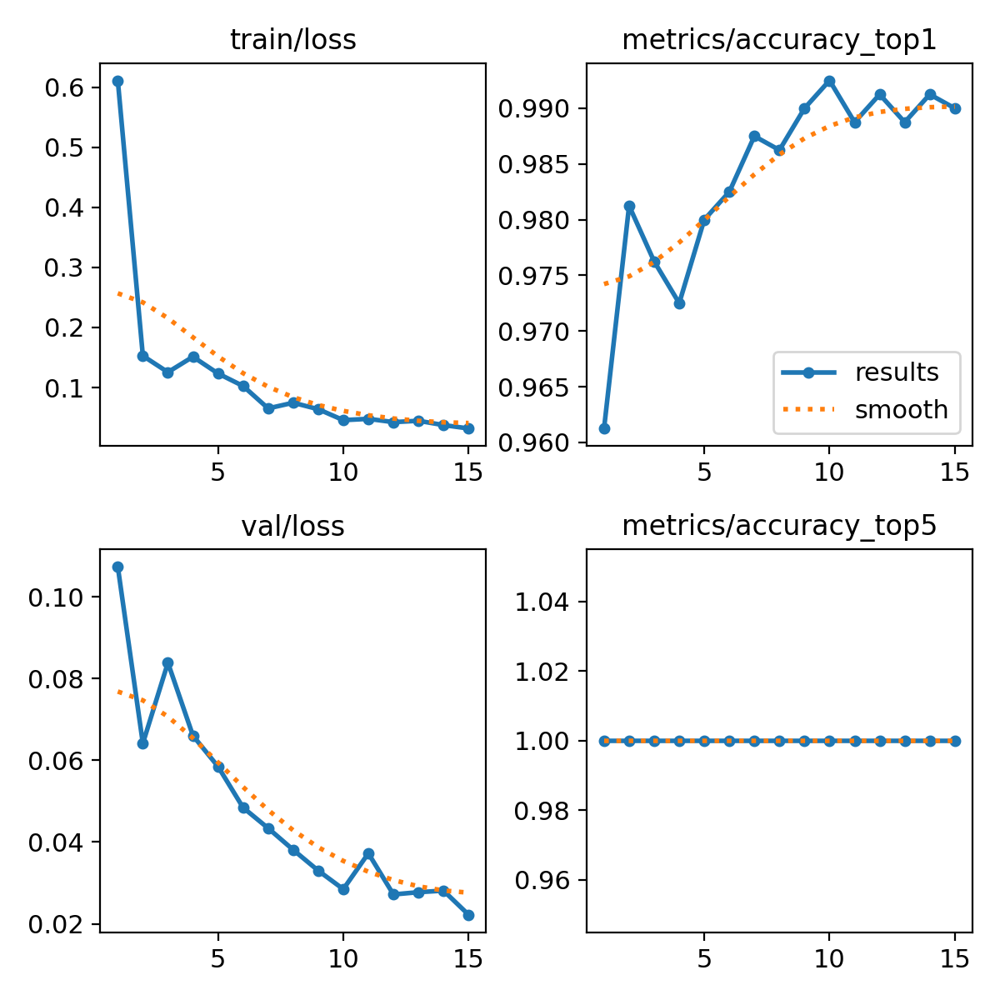

confusion_matrix.png


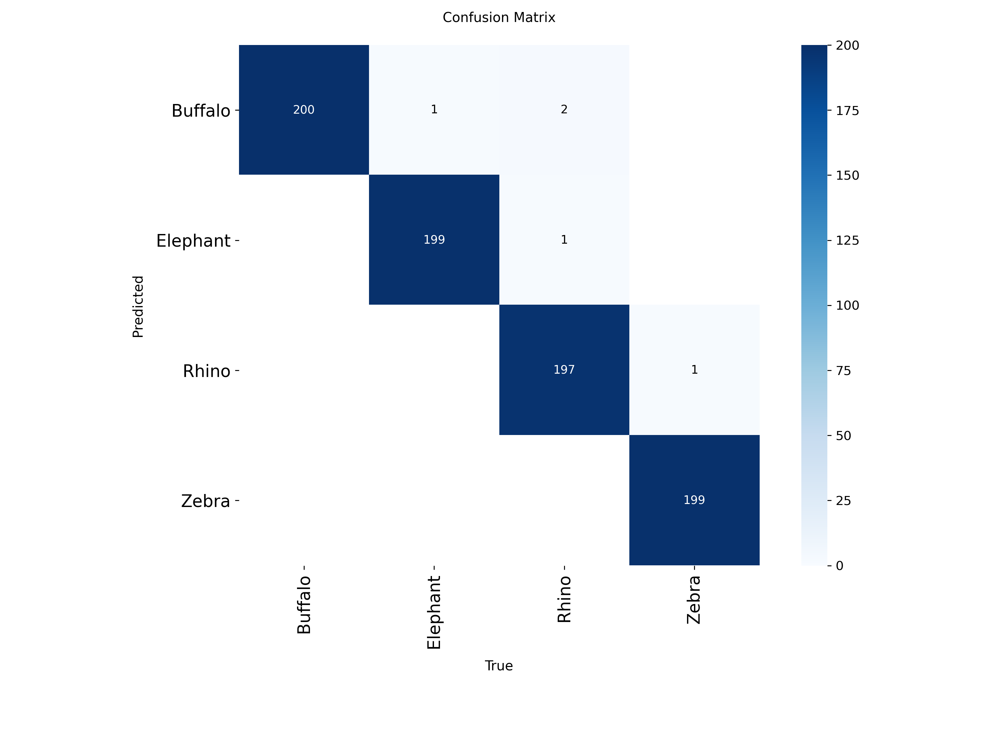

In [15]:
from IPython.display import display, Image
from pathlib import Path

results_dir = Path("/content/runs/animal_yolo")

for filename in ["results.png", "confusion_matrix.png"]:
    path = results_dir / filename

    if path.exists():
        print(filename)
        display(Image(filename=str(path)))
    else:
        print(filename, "not found")

# checking this is converted in to yolo txt

In [17]:

import os

DATASET_DIR = "/content/yolo_animal_dataset"

for folder, subfolders, files in os.walk(DATASET_DIR):
    level = folder.replace(DATASET_DIR, "").count(os.sep)
    print("  " * level + os.path.basename(folder) + "/")

    for filename in files[:3]:
        print("  " * (level + 1) + filename)


yolo_animal_dataset/
  train.cache
  val.cache
  val/
    Zebra/
      29_Zebra_578.jpg
      91_Zebra_317.jpg
      44_Zebra_424.jpg
    Buffalo/
      148_Buffalo_544.jpg
      136_Buffalo_278.jpg
      152_Buffalo_934.jpg
    Rhino/
      173_Rhino_446.jpg
      108_Rhino_909.jpg
      46_Rhino_300.jpg
    Elephant/
      91_Elephant_799.jpg
      94_Elephant_605.jpg
      6_Elephant_344.jpg
  train/
    Zebra/
      147_Zebra_882.jpg
      4_Zebra_786.jpg
      47_Zebra_823.jpg
    Buffalo/
      518_Buffalo_772.jpg
      418_Buffalo_918.jpg
      750_Buffalo_293.jpg
    Rhino/
      475_Rhino_55.jpg
      533_Rhino_943.jpg
      130_Rhino_952.jpg
    Elephant/
      73_Elephant_887.jpg
      663_Elephant_255.jpg
      300_Elephant_614.jpg


In [19]:

from ultralytics import YOLO

# Pretrained YOLO object detection model
detector = YOLO("yolov8n.pt")

print("YOLO object detection model loaded!")


YOLO object detection model loaded!


Saving 22222.jpg to 22222 (3).jpg

image 1/1 /content/22222 (3).jpg: 448x640 1 elephant, 10.5ms
Speed: 2.0ms preprocess, 10.5ms inference, 1.5ms postprocess per image at shape (1, 3, 448, 640)
Results saved to /content/runs/detect/predict


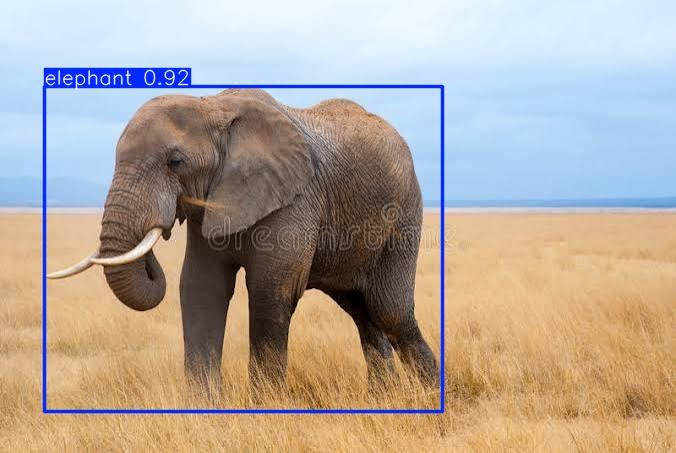

In [22]:
from google.colab import files
from IPython.display import display
from PIL import Image
from pathlib import Path

uploaded = files.upload()
img_path = next(iter(uploaded))

results = detector.predict(
    source=img_path,
    conf=0.10,
    save=True
)

# Get the exact filename and save directory dynamically
save_dir_path = Path(results[0].save_dir)
original_filename = Path(results[0].path).name
predicted_image_path = save_dir_path / original_filename

# Display the predicted image
if predicted_image_path.exists():
    display(Image.open(predicted_image_path))
else:
    print(f"Could not find predicted image at: {predicted_image_path}")

# Load an annotation model

In [23]:

from ultralytics import YOLO

# Pretrained object detector for generating initial annotations
annotation_model = YOLO("yolov8x.pt")

print("Annotation model loaded!")


Annotation model loaded!


# Test automatic annotation on one image

Testing image: /content/animal_dataset/Data/Elephant/Elephant_779.jpg


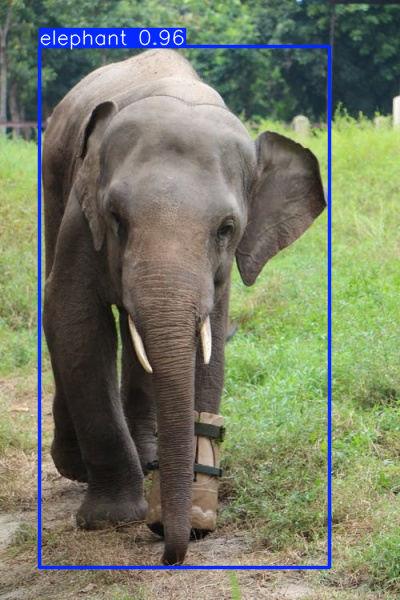

elephant 95.91%


In [24]:

from pathlib import Path
from IPython.display import display
from PIL import Image

# Select one image from your existing dataset
DATASET_DIR = Path("/content/animal_dataset/Data")

test_image = next(
    p for p in (DATASET_DIR / "Elephant").rglob("*")
    if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]
)

print("Testing image:", test_image)

# Predict bounding boxes
results = annotation_model.predict(
    source=str(test_image),
    conf=0.15,
    verbose=False
)

# Display image with bounding boxes
display(Image.fromarray(results[0].plot()[..., ::-1]))

# Print detected classes and confidence
for box in results[0].boxes:
    class_id = int(box.cls[0])
    confidence = float(box.conf[0])
    print(
        results[0].names[class_id],
        f"{confidence:.2%}"
    )


In [25]:

from pathlib import Path

SOURCE = Path("/content/animal_dataset/Data")
OUTPUT = Path("/content/yolo_detection_dataset")

for split in ["train", "val"]:
    (OUTPUT / "images" / split).mkdir(parents=True, exist_ok=True)
    (OUTPUT / "labels" / split).mkdir(parents=True, exist_ok=True)

print("YOLO detection folders created!")


YOLO detection folders created!


In [26]:

import random
import shutil
from pathlib import Path

random.seed(42)

class_names = ["Buffalo", "Elephant", "Rhino", "Zebra"]

# COCO names that may correspond to your target classes.
# These mappings must be reviewed; buffalo and rhino are not
# standard COCO classes.
name_map = {
    "elephant": "Elephant",
    "zebra": "Zebra",
    "cow": "Buffalo",
    "bear": "Rhino"
}

extensions = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

for animal in class_names:
    images = [
        p for p in (SOURCE / animal).rglob("*")
        if p.is_file() and p.suffix.lower() in extensions
    ]
    random.shuffle(images)

    split_at = int(0.8 * len(images))

    for split, selected in [
        ("train", images[:split_at]),
        ("val", images[split_at:])
    ]:
        for index, image_path in enumerate(selected):
            prediction = annotation_model.predict(
                source=str(image_path),
                conf=0.15,
                verbose=False
            )[0]

            lines = []

            for box in prediction.boxes:
                detected_name = prediction.names[int(box.cls[0])].lower()

                if detected_name not in name_map:
                    continue

                mapped_class = name_map[detected_name]

                # Avoid assigning a wrong class to an image
                # based solely on its folder name.
                if mapped_class != animal:
                    continue

                x1, y1, x2, y2 = box.xyxyn[0].tolist()
                cx = (x1 + x2) / 2
                cy = (y1 + y2) / 2
                width = x2 - x1
                height = y2 - y1

                class_id = class_names.index(mapped_class)
                lines.append(
                    f"{class_id} {cx:.6f} {cy:.6f} "
                    f"{width:.6f} {height:.6f}"
                )

            filename = f"{animal}_{index:05d}{image_path.suffix.lower()}"
            target_image = OUTPUT / "images" / split / filename
            target_label = OUTPUT / "labels" / split / f"{Path(filename).stem}.txt"

            shutil.copy2(image_path, target_image)
            target_label.write_text("\n".join(lines))

print("Candidate annotation files created.")
print("Dataset:", OUTPUT)

import random
import shutil
from pathlib import Path

random.seed(42)

class_names = ["Buffalo", "Elephant", "Rhino", "Zebra"]

# COCO names that may correspond to your target classes.
# These mappings must be reviewed; buffalo and rhino are not
# standard COCO classes.
name_map = {
    "elephant": "Elephant",
    "zebra": "Zebra",
    "cow": "Buffalo",
    "bear": "Rhino"
}

extensions = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

for animal in class_names:
    images = [
        p for p in (SOURCE / animal).rglob("*")
        if p.is_file() and p.suffix.lower() in extensions
    ]
    random.shuffle(images)

    split_at = int(0.8 * len(images))

    for split, selected in [
        ("train", images[:split_at]),
        ("val", images[split_at:])
    ]:
        for index, image_path in enumerate(selected):
            prediction = annotation_model.predict(
                source=str(image_path),
                conf=0.15,
                verbose=False
            )[0]

            lines = []

            for box in prediction.boxes:
                detected_name = prediction.names[int(box.cls[0])].lower()

                if detected_name not in name_map:
                    continue

                mapped_class = name_map[detected_name]

                # Avoid assigning a wrong class to an image
                # based solely on its folder name.
                if mapped_class != animal:
                    continue

                x1, y1, x2, y2 = box.xyxyn[0].tolist()
                cx = (x1 + x2) / 2
                cy = (y1 + y2) / 2
                width = x2 - x1
                height = y2 - y1

                class_id = class_names.index(mapped_class)
                lines.append(
                    f"{class_id} {cx:.6f} {cy:.6f} "
                    f"{width:.6f} {height:.6f}"
                )

            filename = f"{animal}_{index:05d}{image_path.suffix.lower()}"
            target_image = OUTPUT / "images" / split / filename
            target_label = OUTPUT / "labels" / split / f"{Path(filename).stem}.txt"

            shutil.copy2(image_path, target_image)
            target_label.write_text("\n".join(lines))

print("Candidate annotation files created.")
print("Dataset:", OUTPUT)


Candidate annotation files created.
Dataset: /content/yolo_detection_dataset
Candidate annotation files created.
Dataset: /content/yolo_detection_dataset


check the annoated file

In [27]:

from pathlib import Path

DATASET = Path("/content/yolo_detection_dataset")

for split in ["train", "val"]:
    image_dir = DATASET / "images" / split
    label_dir = DATASET / "labels" / split

    images = list(image_dir.glob("*"))
    labels = list(label_dir.glob("*.txt"))
    nonempty = sum(bool(p.read_text().strip()) for p in labels)

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("TXT files:", len(labels))
    print("Non-empty labels:", nonempty)
    print("Empty labels:", len(labels) - nonempty)



TRAIN
Images: 3200
TXT files: 3200
Non-empty labels: 2355
Empty labels: 845

VAL
Images: 800
TXT files: 800
Non-empty labels: 590
Empty labels: 210


# visulase the image

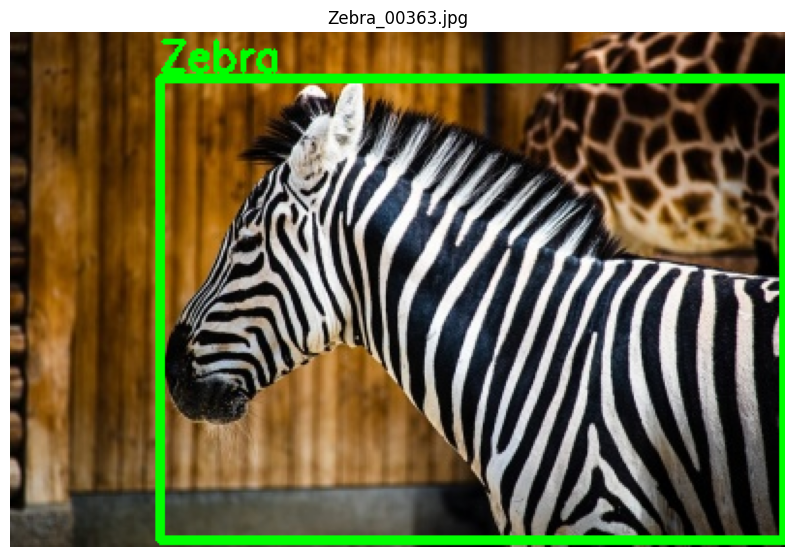

In [28]:

import cv2
import matplotlib.pyplot as plt
from pathlib import Path

DATASET = Path("/content/yolo_detection_dataset")
CLASS_NAMES = ["Buffalo", "Elephant", "Rhino", "Zebra"]

image_dir = DATASET / "images" / "train"
label_dir = DATASET / "labels" / "train"

image_path = None

for p in image_dir.iterdir():
    label_path = label_dir / f"{p.stem}.txt"
    if label_path.exists() and label_path.read_text().strip():
        image_path = p
        break

if image_path is None:
    print("No non-empty labels found. Review annotation generation.")
else:
    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    h, w = image.shape[:2]

    with open(label_dir / f"{image_path.stem}.txt") as f:
        for line in f:
            cls, xc, yc, bw, bh = map(float, line.split())
            x1 = int((xc - bw / 2) * w)
            y1 = int((yc - bh / 2) * h)
            x2 = int((xc + bw / 2) * w)
            y2 = int((yc + bh / 2) * h)

            cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 3)
            cv2.putText(
                image, CLASS_NAMES[int(cls)],
                (x1, max(20, y1 - 8)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.7,
                (0, 255, 0), 2
            )

    plt.figure(figsize=(10, 7))
    plt.imshow(image)
    plt.title(image_path.name)
    plt.axis("off")
    plt.show()


In [29]:

from pathlib import Path

yaml_text = """
path: /content/yolo_detection_dataset
train: images/train
val: images/val

names:
  0: Buffalo
  1: Elephant
  2: Rhino
  3: Zebra
"""

yaml_path = Path("/content/yolo_detection_dataset/data.yaml")
yaml_path.write_text(yaml_text.strip() + "\n")

print(yaml_path.read_text())


path: /content/yolo_detection_dataset
train: images/train
val: images/val

names:
  0: Buffalo
  1: Elephant
  2: Rhino
  3: Zebra



train the custom yolo detector

In [30]:

from ultralytics import YOLO

detector = YOLO("yolov8n.pt")

results = detector.train(
    data="/content/yolo_detection_dataset/data.yaml",
    epochs=30,
    imgsz=640,
    batch=8,
    patience=5,
    project="/content/runs/detect",
    name="animal_detector",
    plots=True,
    save=True
)


Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_detection_dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=animal_detector, nbs=64, nms=None, opset=None, op

results.png


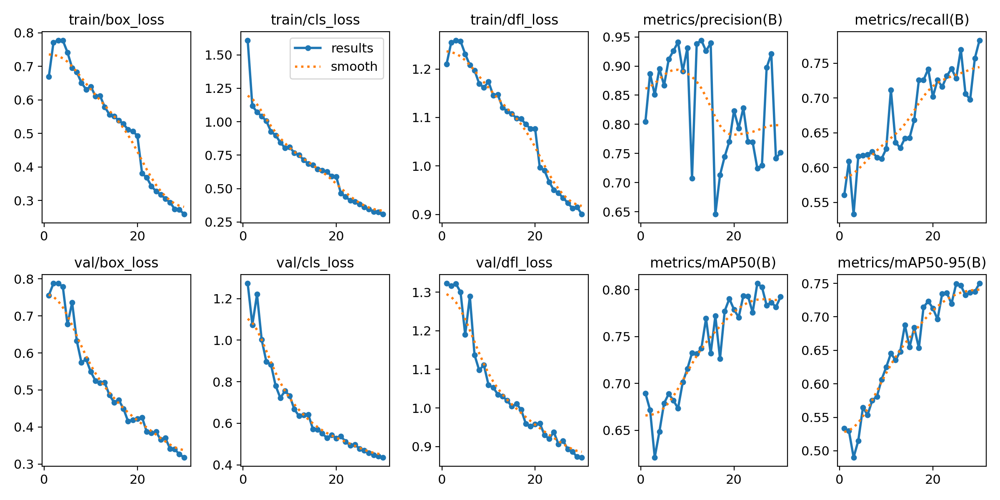

confusion_matrix.png


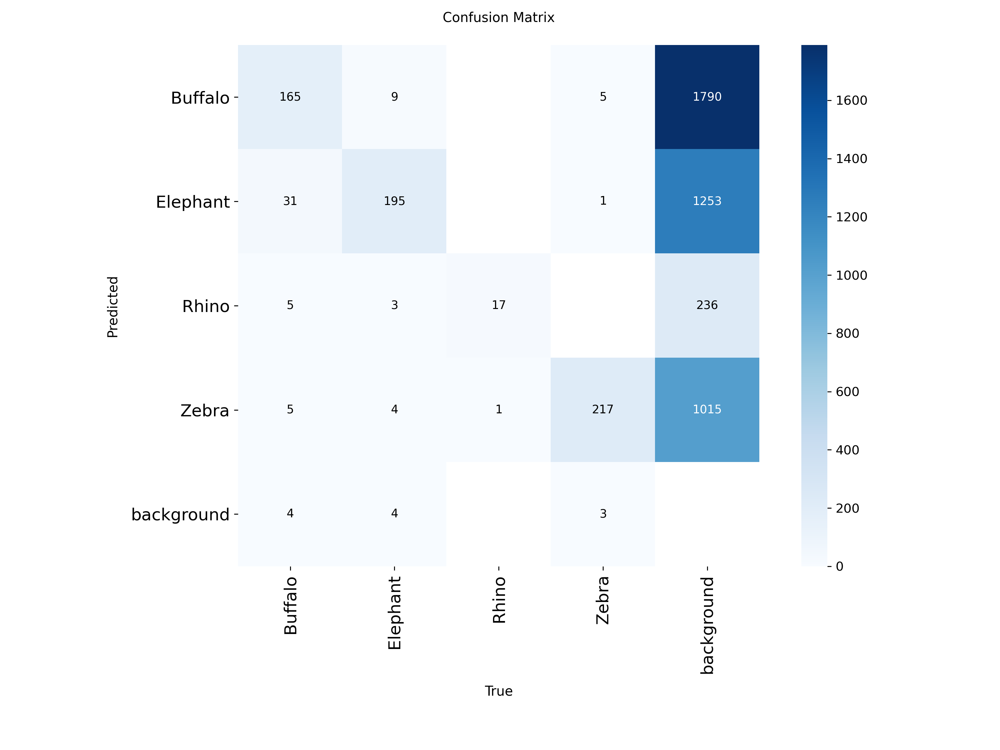

In [31]:

from IPython.display import display, Image
from pathlib import Path

results_dir = Path("/content/runs/detect/animal_detector")

for filename in ["results.png", "confusion_matrix.png"]:
    p = results_dir / filename
    if p.exists():
        print(filename)
        display(Image(filename=str(p)))
    else:
        print(filename, "not found")


validate the model

In [32]:

metrics = detector.val(
    data="/content/yolo_detection_dataset/data.yaml",
    split="val",
    imgsz=640
)

print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)
print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)


Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1143.7±300.6 MB/s, size: 55.7 KB)
val: Scanning /content/yolo_detection_dataset/labels/val.cache... 800 images, 210 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 800/800 145.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 50/50 5.8it/s 8.6s
                   all        800        669      0.751      0.783      0.792      0.749
               Buffalo        173        210      0.734      0.871      0.837      0.772
              Elephant        200        215      0.872      0.952      0.963      0.918
                 Rhino         18         18      0.475      0.389      0.419      0.407
                 Zebra        199        226      0.922       0.92      0.948      0.898
Speed: 1.1ms preprocess, 4.1ms i

cofusion matrix

confusion_matrix.png


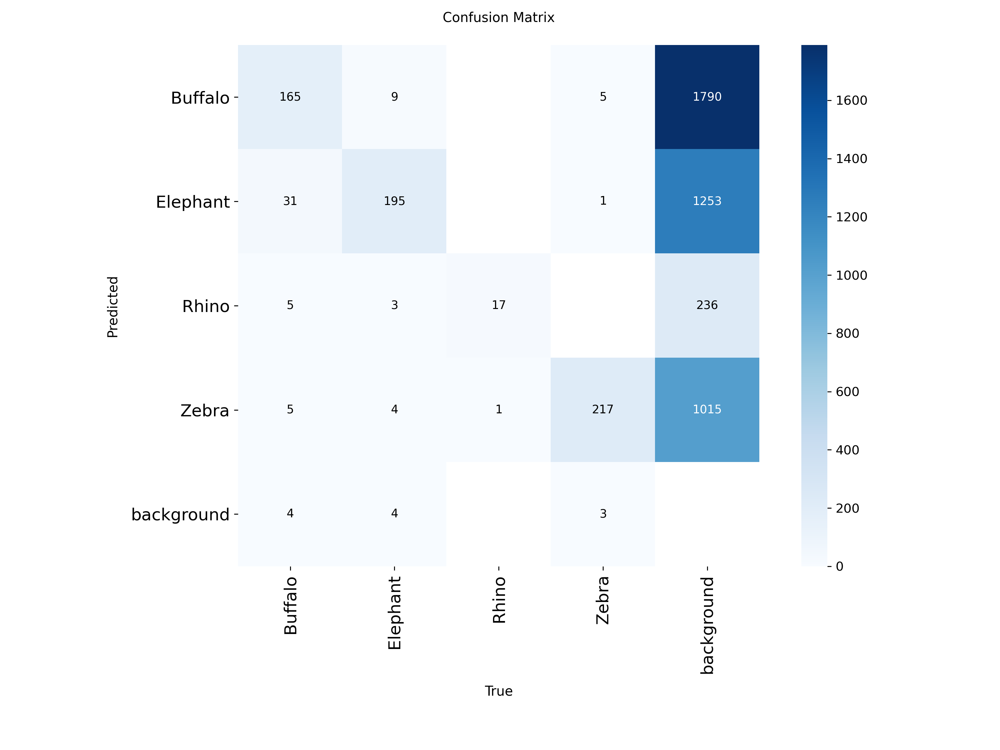

confusion_matrix_normalized.png


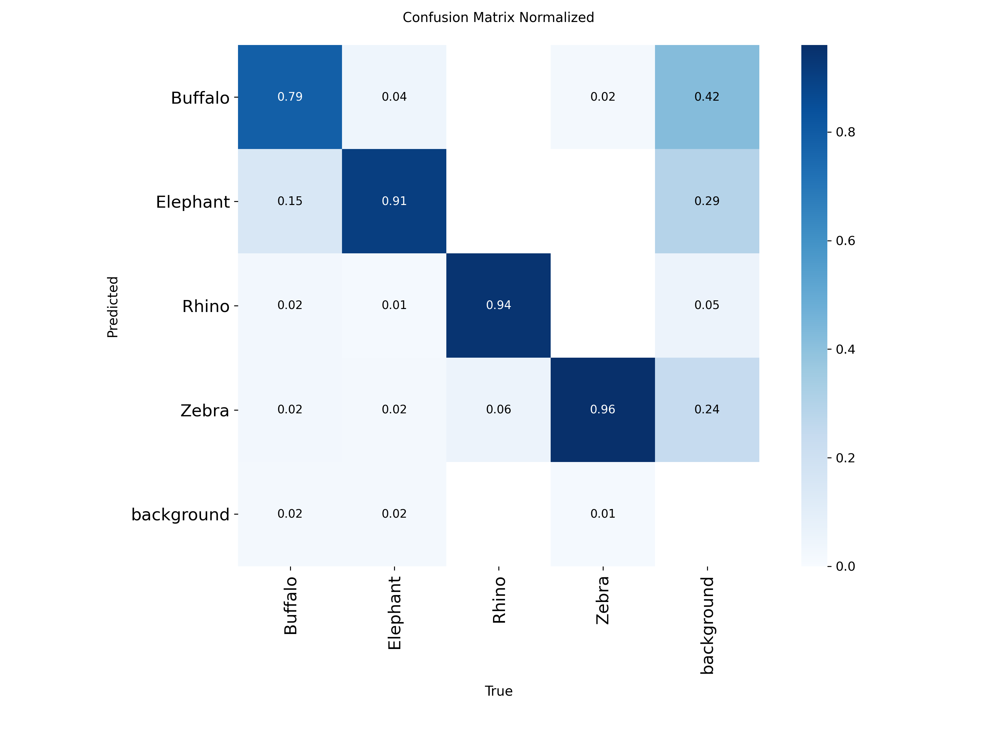

In [33]:

from pathlib import Path
from IPython.display import display, Image

results_dir = Path("/content/runs/detect/animal_detector")

for filename in [
    "confusion_matrix.png",
    "confusion_matrix_normalized.png"
]:
    path = results_dir / filename

    if path.exists():
        print(filename)
        display(Image(filename=str(path)))


upload new  image

In [34]:

from google.colab import files

uploaded = files.upload()
image_path = next(iter(uploaded))

print("Uploaded:", image_path)


Saving images.jpg to images.jpg
Uploaded: images.jpg



image 1/1 /content/images.jpg: 320x640 3 Elephants, 12.3ms
Speed: 2.4ms preprocess, 12.3ms inference, 2.3ms postprocess per image at shape (1, 3, 320, 640)
Results saved to /content/runs/detect/animal_predictions


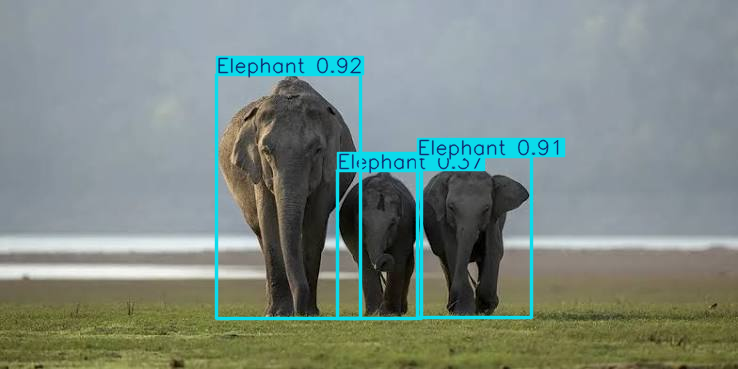

In [35]:

from IPython.display import display
from PIL import Image

predictions = detector.predict(
    source=image_path,
    conf=0.25,
    imgsz=640,
    save=True,
    project="/content/runs/detect",
    name="animal_predictions",
    exist_ok=True
)

result = predictions[0]

display(Image.fromarray(result.plot()[..., ::-1]))


print the detect the model

In [36]:

result = predictions[0]

if result.boxes is None or len(result.boxes) == 0:
    print("No animals detected.")
else:
    for box in result.boxes:
        class_id = int(box.cls[0])
        confidence = float(box.conf[0])
        print(
            f"{result.names[class_id]}: "
            f"{confidence * 100:.2f}% confidence"
        )


Elephant: 92.46% confidence
Elephant: 90.58% confidence
Elephant: 37.36% confidence


save the best trained model

In [37]:

from pathlib import Path
import shutil

best_model = Path(
    "/content/runs/detect/animal_detector/weights/best.pt"
)

if best_model.exists():
    shutil.copy2(best_model, "/content/best_animal_yolo.pt")
    print("Model saved:", "/content/best_animal_yolo.pt")
else:
    print("Best model not found. Check Cell 27 training output.")


Model saved: /content/best_animal_yolo.pt


download the model

In [38]:

from google.colab import files

files.download("/content/best_animal_yolo.pt")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [39]:

from ultralytics import YOLO

detector = YOLO("/content/best_animal_yolo.pt")

print("Custom animal detector loaded successfully!")
print(detector.names)


Custom animal detector loaded successfully!
{0: 'Buffalo', 1: 'Elephant', 2: 'Rhino', 3: 'Zebra'}


In [42]:
from google.colab import files
import os

# Search for any valid .ipynb files in the /content directory
notebook_files = [f for f in os.listdir('/content') if f.endswith('.ipynb')]

if notebook_files:
    print(f"Found notebook: {notebook_files[0]}")
    files.download(os.path.join('/content', notebook_files[0]))
else:
    print("No .ipynb files found in your /content directory.")
    print("\nTo download this notebook, use the Colab menu:")
    print("Go to: File -> Download -> Download .ipynb")

No .ipynb files found in your /content directory.

To download this notebook, use the Colab menu:
Go to: File -> Download -> Download .ipynb
